Build a reliable patent search query for the smart glasses sector using PATSTAT. Our sector is Smart Glasses.

In [2]:
# import the libraries

from datetime import date

import pandas as pd
from sqlalchemy import func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # applications
    TLS202_APPLN_TITLE,         # titles
    TLS203_APPLN_ABSTR,         # abstracts
    TLS206_PERSON,              # persons (applicants and inventors)
    TLS207_PERS_APPLN,          # person <-> application links
    TLS209_APPLN_IPC,           # IPC classification
    TLS224_APPLN_CPC,           # CPC classification
    TLS231_INPADOC_LEGAL_EVENT, # legal events
)

patstat = PatstatClient(env='TEST')          # default: env="TEST"; use PatstatClient(env="PROD") for the full database
db = patstat.orm()                 # SQLAlchemy session used by all ORM queries below

KEYWORDS, IPC and CPC codes are to be verified!

In [3]:
# Keywords searched (case-insensitive) in titles and abstracts

SMART_GLASSES_KEYWORDS = (
    "smart glasses",
    "wearable device",
    "smart eyewear",
    "intelligent glasses",
    "augmented reality glasses",
    "AR glasses",
    "mixed reality glasses",
    "optical see-through display",
    "head-mounted display",
    "head mounted display",
    "head-worn display",
    "eyeglass-type display",
    "wearable display",
    "near-eye display",
    "waveguide display",
    "smart spectacles",
    "computer glasses",
    "hands-free wearable display",
)


In [4]:
# IPC codes: candidate prefixes for smart glasses
SMART_GLASSES_IPC_CODES = (
    "G02B27/01",  # Head-up displays; broader than smart glasses
    "G02C",       # Spectacles; broad, so validate carefully
)

# CPC codes: candidate prefixes for smart glasses
SMART_GLASSES_CPC_CODES = (
    "G02B27/017",  # Head-mounted displays
    "H04N13/332",  # Certain stereoscopic display systems
)

In [5]:
def keyword_condition(terms):
    """OR-condition: any term appears in the title or in the abstract (case-insensitive)."""
    title = func.lower(TLS202_APPLN_TITLE.appln_title)
    abstract = func.lower(TLS203_APPLN_ABSTR.appln_abstract)
    return or_(
        *(title.like(f"%{t.lower()}%") for t in terms),
        *(abstract.like(f"%{t.lower()}%") for t in terms),
    )


def symbol_prefix_condition(symbol_column, codes):
    """OR-condition: the blank-stripped classification symbol starts with one of the codes."""
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))


# Base columns shown for every application
APPLN_COLUMNS = (
    TLS201_APPLN.appln_id,
    TLS201_APPLN.appln_auth,
    TLS201_APPLN.appln_nr,
    TLS201_APPLN.appln_kind,
    TLS201_APPLN.appln_filing_date,
)


def query_by_keywords(*columns):
    """Applications whose title or abstract contains an AI keyword."""
    return (
        db.query(*columns)
        .select_from(TLS201_APPLN)
        .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_condition(SMART_GLASSES_KEYWORDS))
    )


def query_by_ipc(*columns):
    """Applications with at least one IPC symbol in the AI list."""
    return (
        db.query(*columns)
        .select_from(TLS201_APPLN)
        .join(TLS209_APPLN_IPC, TLS201_APPLN.appln_id == TLS209_APPLN_IPC.appln_id)
        .filter(symbol_prefix_condition(TLS209_APPLN_IPC.ipc_class_symbol, SMART_GLASSES_IPC_CODES))
    )


def query_by_cpc(*columns):
    """Applications with at least one CPC symbol in the AI list."""
    return (
        db.query(*columns)
        .select_from(TLS201_APPLN)
        .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
        .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, SMART_GLASSES_CPC_CODES))
    )

In [6]:
# keywords search

q_keywords = query_by_keywords(
    *APPLN_COLUMNS,
    TLS202_APPLN_TITLE.appln_title,
    TLS203_APPLN_ABSTR.appln_abstract,
).distinct()

df_keywords = patstat.df(q_keywords)
df_keywords.head(10)

,appln_id,appln_auth,appln_nr,appln_kind,appln_filing_date,appln_title,appln_abstract
0,419636588,US,201213728511,A,2012-12-27,Augmented Reality Worksite,A system and method for coordinating machines ...
1,518904888,CN,201910451909,A,2019-05-28,Power AR intelligent tour inspection device,The invention discloses a power AR intelligent...
2,482803666,CN,201710366180,A,2017-05-23,Mobile internet intelligent wearable device,The invention relates to a mobile internet int...
3,456458540,KR,20140151236,A,2014-11-03,GESTURE RECOGNITION APPARATUS FOR VEHICLE,Disclosed is a gesture recognition apparatus f...
4,567714532,CN,202111451620,A,2021-12-01,Wearable massage power assisting device for sp...,"The invention relates to a wearable device, in..."
5,475571093,CN,201610648458,A,2016-08-08,Indoor positioning and identity recognizing-ba...,The invention relates to an indoor positioning...
6,472733104,US,201514734696,A,2015-06-09,Energy management using a wearable device,Energy management using a wearable device is d...
7,520611366,US,201715461287,A,2017-03-16,Validation of camera calibration data using au...,Methods and systems for collecting camera cali...
8,497140156,CN,201711387733,A,2017-12-20,LDHs (Layered Double Hydroxides) based water e...,The invention discloses an LDHs (Layered Doubl...
9,413784931,JP,2012127450,A,2012-06-04,IMAGE DISPLAY DEVICE AND HEAD MOUNTED DISPLAY,PROBLEM TO BE SOLVED: To provide an image disp...


In [7]:
# ipc search

q_ipc = query_by_ipc(*APPLN_COLUMNS, TLS209_APPLN_IPC.ipc_class_symbol).distinct()

df_ipc = patstat.df(q_ipc)
df_ipc.head()

,appln_id,appln_auth,appln_nr,appln_kind,appln_filing_date,ipc_class_symbol
0,53273445,US,75790577,A,1977-01-10,G02C 5/20
1,53273445,US,75790577,A,1977-01-10,G02C 5/22
2,31037131,JP,11485480,A,1980-08-22,G02C 13/00
3,51165047,US,47390990,A,1990-02-02,G02C 13/00
4,49638978,US,32688894,A,1994-10-21,G02C 7/06


In [8]:
# cpc search

q_cpc = query_by_cpc(*APPLN_COLUMNS, TLS224_APPLN_CPC.cpc_class_symbol).distinct()

df_cpc = patstat.df(q_cpc)
df_cpc.head(10)

,appln_id,appln_auth,appln_nr,appln_kind,appln_filing_date,cpc_class_symbol
0,54099906,US,90910604,A,2004-07-30,G02B 27/017
1,338453194,US,76898110,A,2010-04-28,H04N 13/332
2,413784931,JP,2012127450,A,2012-06-04,G02B 27/017
3,413784931,JP,2012127450,A,2012-06-04,G02B 27/0172
4,415399241,KR,20120074332,A,2012-07-09,H04N 13/332
5,442975882,DE,102014202609,A,2014-02-13,G02B 27/017
6,442975882,DE,102014202609,A,2014-02-13,G02B 27/0172
7,478346310,US,201615344430,A,2016-11-04,G02B 27/0172
8,480941002,WO,2015099852,W,2015-12-30,G02B 27/017
9,524191300,US,201916548802,A,2019-08-22,G02B 27/0172


In [9]:
# combine the three search strategies:

appln_id = TLS201_APPLN.appln_id.label("appln_id")

ai_ids = (
    query_by_keywords(appln_id)
    .union(query_by_ipc(appln_id), query_by_cpc(appln_id))
    .subquery()
)

q_ai = (
    db.query(*APPLN_COLUMNS, TLS202_APPLN_TITLE.appln_title)
    .select_from(TLS201_APPLN)
    .join(ai_ids, TLS201_APPLN.appln_id == ai_ids.c.appln_id)
    .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
    .distinct()
    .order_by(TLS201_APPLN.appln_filing_date)
)

df_ai = patstat.df(q_ai)
df_ai.head(10)

,appln_id,appln_auth,appln_nr,appln_kind,appln_filing_date,appln_title
0,53273445,US,75790577,A,1977-01-10,Adjustable eyeglass temple
1,31037131,JP,11485480,A,1980-08-22,DIGITAL METHOD OF AND APPARATUS FOR AUTOMATICA...
2,51165047,US,47390990,A,1990-02-02,Ultrasonic cleaning system for fluorescent lig...
3,35669401,JP,28769392,A,1992-10-26,HEAD MOUNTED DISPLAY SYSTEM
4,49638978,US,32688894,A,1994-10-21,Ophthalmic glass of high refractive index
5,52158723,US,60465996,A,1996-02-21,Bolt and engagement aperture lens joint struct...
6,34561282,JP,21798897,A,1997-07-28,METHOD AND APPARATUS FOR STERILIZATION OF OPHT...
7,54275580,US,94605701,A,2001-09-04,Combined LOAS and LIDAR system
8,37516591,JP,2001345149,A,2001-11-09,CLOUDING RESISTANT MEMBER
9,37934508,JP,2002359338,A,2002-12-11,INSTRUMENT FOR MEASURING SHAPE OF SPECTACLE FRAME


In [10]:
# How much does each strategy contribute? (counts of distinct applications)
pd.Series(
    {
        "keywords": df_keywords["appln_id"].nunique(),
        "IPC": df_ipc["appln_id"].nunique(),
        "CPC": df_cpc["appln_id"].nunique(),
        "union (AI set)": df_ai["appln_id"].nunique(),
    },
    name="applications",
)

keywords          32
IPC               54
CPC               25
union (AI set)    87
Name: applications, dtype: int64

Try more advanced search techniques to identify smart-glasses patents more accurately.
The main idea is to compare two ways of finding relevant patents:

- Lexical search (BM25): finds patents using the words they contain. I give it a query and BM25 ranks patent abstracts based on the relevance and frequency of matching words.
- Semantic search (Patent SBERT): finds patents based on the meaning of their text, even when different words are used. I give technology sector description and model converts it and patent abstract into vectors, then ranks the abstracts by semantic similarity.


In [13]:
import re

import matplotlib.pyplot as plt
import numpy as np
import umap
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

In [14]:
# Configuration
# does not retrieve patents

from datetime import date

# Candidate CPC code: verify against the current CPC scheme.
# This is a starting point for head-mounted display technology.
CANDIDATE_CPC = "G02B  27/017"

# Include patent applications filed from 2005 onwards.
MIN_FILING_DATE = date(2005, 1, 1)

# Language of patent abstracts
ABSTRACT_LANGUAGE = "en"

# Patent-domain sentence embedding model
SBERT_MODEL = "graziasveva93/sbert-adapt-ub"

# Number of rows shown in ranking tables
TOP_N_DISPLAY = 5

# Number of top-ranked patents compared between methods
TOP_K = 100

# Reproducible UMAP projection
RANDOM_STATE = 42

SMART_GLASSES_DESCRIPTION = """
Technology for wearable eyeglass-form devices that integrate electronic
components such as displays, cameras, sensors, processors and wireless
connectivity into glasses or spectacles. These devices provide digital
information in the user's field of view, augmented reality or mixed reality
experiences, hands-free access to information, and interaction with digital
content through voice, gestures, eye tracking or other input methods.
Relevant technologies may include near-eye displays, optical see-through
displays, optical waveguides, miniature projectors and display systems
integrated into eyeglass frames. The focus is on glasses-form wearable
computing devices rather than conventional spectacles or general-purpose
head-mounted displays that are not designed as glasses.
"""


In [17]:

# 6.2 Diagnose the smart-glasses candidate query

from sqlalchemy import func

# Test 1: Inspect CPC symbols resembling G02B27/017
cpc_test = (
    db.query(TLS224_APPLN_CPC.cpc_class_symbol)
    .filter(
        TLS224_APPLN_CPC.cpc_class_symbol.like("%G02B27%")
    )
    .distinct()
    .limit(30)
)

cpc_symbols = patstat.df(cpc_test)

print("Test 1 — CPC symbols resembling G02B27:")
print(cpc_symbols.to_string(index=False) if not cpc_symbols.empty
      else "No matching CPC symbols found.")

# Test 2: Count applications with any matching G02B27 CPC symbol
cpc_count = (
    db.query(func.count())
    .select_from(TLS201_APPLN)
    .join(
        TLS224_APPLN_CPC,
        TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id,
    )
    .filter(
        TLS224_APPLN_CPC.cpc_class_symbol.like("%G02B27%")
    )
)

print("\nTest 2 — Applications with CPC symbols containing G02B27:")
print(cpc_count.scalar())

# Test 3: Check whether the filing-date filter leaves any applications
date_count = (
    db.query(func.count())
    .select_from(TLS201_APPLN)
    .join(
        TLS224_APPLN_CPC,
        TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id,
    )
    .filter(
        TLS224_APPLN_CPC.cpc_class_symbol.like("%G02B27%"),
        TLS201_APPLN.appln_filing_date >= MIN_FILING_DATE,
    )
)

print("\nTest 3 — After filing-date filter:")
print(date_count.scalar())

# Test 4: Check abstracts and language filter
abstract_count = (
    db.query(func.count())
    .select_from(TLS201_APPLN)
    .join(
        TLS224_APPLN_CPC,
        TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id,
    )
    .join(
        TLS203_APPLN_ABSTR,
        TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id,
    )
    .filter(
        TLS224_APPLN_CPC.cpc_class_symbol.like("%G02B27%"),
        TLS201_APPLN.appln_filing_date >= MIN_FILING_DATE,
        TLS203_APPLN_ABSTR.appln_abstract.isnot(None),
        TLS203_APPLN_ABSTR.appln_abstract_lg == ABSTRACT_LANGUAGE,
    )
)

print("\nTest 4 — After requiring English abstracts:")
print(abstract_count.scalar())


Test 1 — CPC symbols resembling G02B27:
No matching CPC symbols found.

Test 2 — Applications with CPC symbols containing G02B27:
0

Test 3 — After filing-date filter:
0

Test 4 — After requiring English abstracts:
0


In [18]:
# Inspect the stored CPC symbols, allowing for spaces

cpc_test = (
    db.query(TLS224_APPLN_CPC.cpc_class_symbol)
    .filter(
        TLS224_APPLN_CPC.cpc_class_symbol.like("%G02B%")
    )
    .distinct()
    .limit(50)
)

cpc_symbols = patstat.df(cpc_test)

print("CPC symbols containing G02B:")
if cpc_symbols.empty:
    print("No matching symbols found.")
else:
    print(cpc_symbols.to_string(index=False))

# Check whether the CPC table contains any records at all
total_cpc = db.query(func.count()).select_from(TLS224_APPLN_CPC).scalar()
print("\nTotal CPC records in this database:", total_cpc)

CPC symbols containing G02B:
cpc_class_symbol
    G02B   6/024
    G02B   6/032
  G02B   6/03616
  G02B   6/03622
  G02B   6/03633
  G02B   6/03638
    G02B   6/036
     G02B   6/14
     G02B   6/00
   G02B   6/0055
   G02B   6/0063
   G02B   6/0073
   G02B   6/0076
     G02B  26/06
     G02B   5/10
   G02B   6/3816
   G02B   6/3821
   G02B   6/3849
   G02B   6/4225
  G02B2006/12138
    G02B   6/506
     G02B   6/54
   G02B   6/2821
  G02B   6/29338
    G02B   5/008
   G02B  21/0004
   G02B  27/0075
     G02B   1/18
    G02B   5/285
     G02B  23/22
   G02B  27/0006
   G02B  13/0075
     G02B  13/06
     G02B   5/00
     G02B   6/10
   G02B   6/4432
   G02B   6/3512
   G02B   6/3568
   G02B   6/3578
    G02B   5/021
   G02B   6/0218
   G02B   6/3616
   G02B   6/4478
   G02B   6/4416
   G02B   6/4479
    G02B   7/021
    G02B   7/023
     G02B  27/62
   G02B   6/3866
   G02B   6/3873

Total CPC records in this database: 1948561


In [19]:

# Check whether the target CPC code exists, allowing for spaces

cpc_target = (
    db.query(TLS224_APPLN_CPC.cpc_class_symbol)
    .filter(
        TLS224_APPLN_CPC.cpc_class_symbol.like("%G02B%27/017%")
    )
    .distinct()
    .limit(30)
)

target_symbols = patstat.df(cpc_target)

print("Matching target CPC symbols:")
if target_symbols.empty:
    print("No matching symbols found.")
else:
    print(target_symbols.to_string(index=False))


Matching target CPC symbols:
cpc_class_symbol
    G02B  27/017
   G02B  27/0172
   G02B2027/0178
   G02B  27/0176


In [20]:
# Step 6.2


# 6.2 Candidate technological space
# Smart glasses / head-mounted display technology
# English abstracts, filed from 2005 onwards

q_candidates = (
    db.query(
        *APPLN_COLUMNS,
        TLS202_APPLN_TITLE.appln_title,
        TLS203_APPLN_ABSTR.appln_abstract,
        TLS224_APPLN_CPC.cpc_class_symbol,
    )
    .select_from(TLS201_APPLN)
    .join(
        TLS224_APPLN_CPC,
        TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id,
    )
    .join(
        TLS203_APPLN_ABSTR,
        TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id,
    )
    .outerjoin(
        TLS202_APPLN_TITLE,
        TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id,
    )
    .filter(
        TLS224_APPLN_CPC.cpc_class_symbol.like("%G02B%27/017%"),
        TLS201_APPLN.appln_filing_date >= MIN_FILING_DATE,
        TLS203_APPLN_ABSTR.appln_abstract.isnot(None),
        TLS203_APPLN_ABSTR.appln_abstract_lg == ABSTRACT_LANGUAGE,
    )
    .distinct()
)

# Retrieve and inspect candidate applications
candidates_raw = patstat.df(q_candidates)

print("Rows returned by PATSTAT:", len(candidates_raw))
print("Columns:", candidates_raw.columns.tolist())

if not candidates_raw.empty:
    candidates = (
        candidates_raw
        .dropna(subset=["appln_abstract"])
        .drop_duplicates(subset=["appln_id"])
        .reset_index(drop=True)
    )

    print(f"Candidate applications: {len(candidates):,}")
    display(candidates.head())
else:
    print(
        "No candidate applications found. "
        "Check the CPC, date, and abstract filters."
    )


Rows returned by PATSTAT: 27
Columns: ['appln_id', 'appln_auth', 'appln_nr', 'appln_kind', 'appln_filing_date', 'appln_title', 'appln_abstract', 'cpc_class_symbol']
Candidate applications: 17


,appln_id,appln_auth,appln_nr,appln_kind,appln_filing_date,appln_title,appln_abstract,cpc_class_symbol
0,413784931,JP,2012127450,A,2012-06-04,IMAGE DISPLAY DEVICE AND HEAD MOUNTED DISPLAY,PROBLEM TO BE SOLVED: To provide an image disp...,G02B 27/017
1,478346310,US,201615344430,A,2016-11-04,Eye tracking using optical flow,"An eye tracking system, images the surface (e....",G02B 27/0172
2,480941002,WO,2015099852,W,2015-12-30,METHOD OF EXPERIENCING UNMANNED AERIAL VEHICLE...,A method of experiencing an unmanned aerial ve...,G02B 27/017
3,524191300,US,201916548802,A,2019-08-22,Tiled waveguide display with a wide field-of-view,"A waveguide display includes light sources, a ...",G02B 27/0172
4,508270055,US,201815879372,A,2018-01-24,Drones generating various air flow effects aro...,Systems and methods described herein are direc...,G02B 27/017


In [21]:
# helper functions
def rank_by(df, score_col):
    """Return a copy of df sorted by score_col (descending) with a 1-based rank column."""
    ranked = df.sort_values(score_col, ascending=False).reset_index(drop=True)
    ranked.insert(0, "rank", np.arange(1, len(ranked) + 1))
    return ranked


def top_table(ranked, score_col, n=TOP_N_DISPLAY):
    """The n best-ranked applications, with the columns needed to judge them."""
    cols = ["rank", "appln_id", "appln_title", "appln_filing_date", score_col, "appln_abstract"]
    return ranked[cols].head(n)


def top_k_ids(ranked, k=TOP_K):
    """The set of appln_ids among the k best-ranked applications."""
    return set(ranked["appln_id"].head(k))

In [22]:
# method BM25 (lexical)

TOKEN_PATTERN = re.compile(r"\b[a-zA-Z0-9]+\b")


def tokenize(text):
    """Lower-case alphanumeric tokens."""
    return TOKEN_PATTERN.findall(text.lower())


bm25 = BM25Okapi([tokenize(text) for text in candidates["appln_abstract"].astype(str)])
candidates["bm25_score"] = bm25.get_scores(tokenize(SMART_GLASSES_DESCRIPTION))

ranked_bm25 = rank_by(candidates, "bm25_score")
top_table(ranked_bm25, "bm25_score")

,rank,appln_id,appln_title,appln_filing_date,bm25_score,appln_abstract
0,1,538857206,Location information display device and survey...,2020-04-01,39.199485,A head-mounted display device has more conveni...
1,2,539273931,Nose pad and glasses/eye appliance or face pro...,2019-04-05,35.908355,The invention provides a nose pad and a glasse...
2,3,508270055,Drones generating various air flow effects aro...,2018-01-24,34.567374,Systems and methods described herein are direc...
3,4,580591597,"SYSTEMS, DEVICES, AND/OR PROCESSES FOR DYNAMIC...",2021-03-31,32.896146,Subject matter disclosed herein relates to sys...
4,5,528995829,Augmented reality system to map and visualize ...,2018-10-07,29.855498,A method and system to receive information fro...


In [33]:
# method 2: Patent SBERT-adapt-ub (semantic)

model = SentenceTransformer(SBERT_MODEL)

abstract_embeddings = model.encode(
    candidates["appln_abstract"].astype(str).tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)
smart_glasses_embedding = model.encode(SMART_GLASSES_DESCRIPTION, convert_to_numpy=True, normalize_embeddings=True)

print("Embedding matrix:", abstract_embeddings.shape)   # (n_patents, embedding_dim)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding matrix: (17, 384)


In [34]:
candidates["sbert_similarity"] = abstract_embeddings @ smart_glasses_embedding   # cosine similarity

ranked_sbert = rank_by(candidates, "sbert_similarity")
top_table(ranked_sbert, "sbert_similarity")

,rank,appln_id,appln_title,appln_filing_date,sbert_similarity,appln_abstract
0,1,538857206,Location information display device and survey...,2020-04-01,0.861313,A head-mounted display device has more conveni...
1,2,478346310,Eye tracking using optical flow,2016-11-04,0.845125,"An eye tracking system, images the surface (e...."
2,3,494846332,Remote follow-up stereoscopic vision system,2017-12-01,0.825436,The invention discloses a remote follow-up ste...
3,4,508270055,Drones generating various air flow effects aro...,2018-01-24,0.774295,Systems and methods described herein are direc...
4,5,580591597,"SYSTEMS, DEVICES, AND/OR PROCESSES FOR DYNAMIC...",2021-03-31,0.767083,Subject matter disclosed herein relates to sys...


In [35]:
n = TOP_N_DISPLAY
comparison_top = pd.DataFrame(
    {
        "rank": range(1, n + 1),
        "BM25 appln_id": ranked_bm25["appln_id"].head(n).values,
        "BM25 title": ranked_bm25["appln_title"].head(n).values,
        "SBERT appln_id": ranked_sbert["appln_id"].head(n).values,
        "SBERT title": ranked_sbert["appln_title"].head(n).values,
    }
)
comparison_top

,rank,BM25 appln_id,BM25 title,SBERT appln_id,SBERT title
0,1,538857206,Location information display device and survey...,538857206,Location information display device and survey...
1,2,539273931,Nose pad and glasses/eye appliance or face pro...,478346310,Eye tracking using optical flow
2,3,508270055,Drones generating various air flow effects aro...,494846332,Remote follow-up stereoscopic vision system
3,4,580591597,"SYSTEMS, DEVICES, AND/OR PROCESSES FOR DYNAMIC...",508270055,Drones generating various air flow effects aro...
4,5,528995829,Augmented reality system to map and visualize ...,580591597,"SYSTEMS, DEVICES, AND/OR PROCESSES FOR DYNAMIC..."


In [36]:
k = min(TOP_K, len(candidates))   # cannot take more patents than there are candidates

bm25_top_ids = top_k_ids(ranked_bm25, k)
sbert_top_ids = top_k_ids(ranked_sbert, k)
overlap = bm25_top_ids & sbert_top_ids

print(f"Candidates: {len(candidates)} | top-K: {k}")
print(f"Patents appearing in both top-{k} lists: {len(overlap)}")
print(f"Top-{k} overlap: {len(overlap) / k:.1%}")

candidates["in_bm25_top"] = candidates["appln_id"].isin(bm25_top_ids)
candidates["in_sbert_top"] = candidates["appln_id"].isin(sbert_top_ids)

Candidates: 17 | top-K: 17
Patents appearing in both top-17 lists: 17
Top-17 overlap: 100.0%


/opt/conda/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


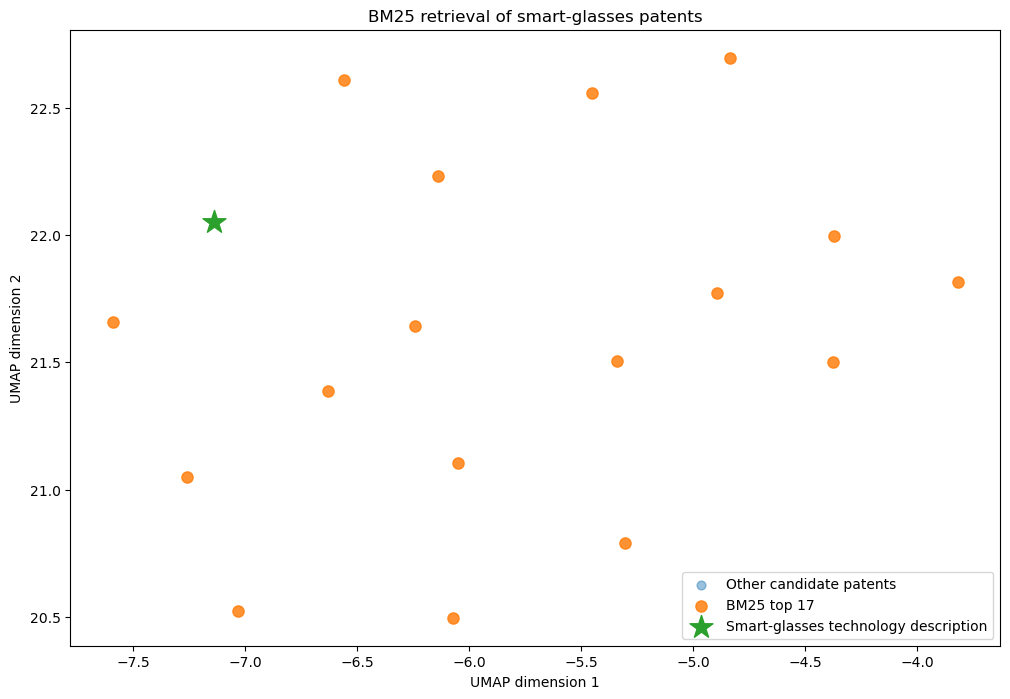

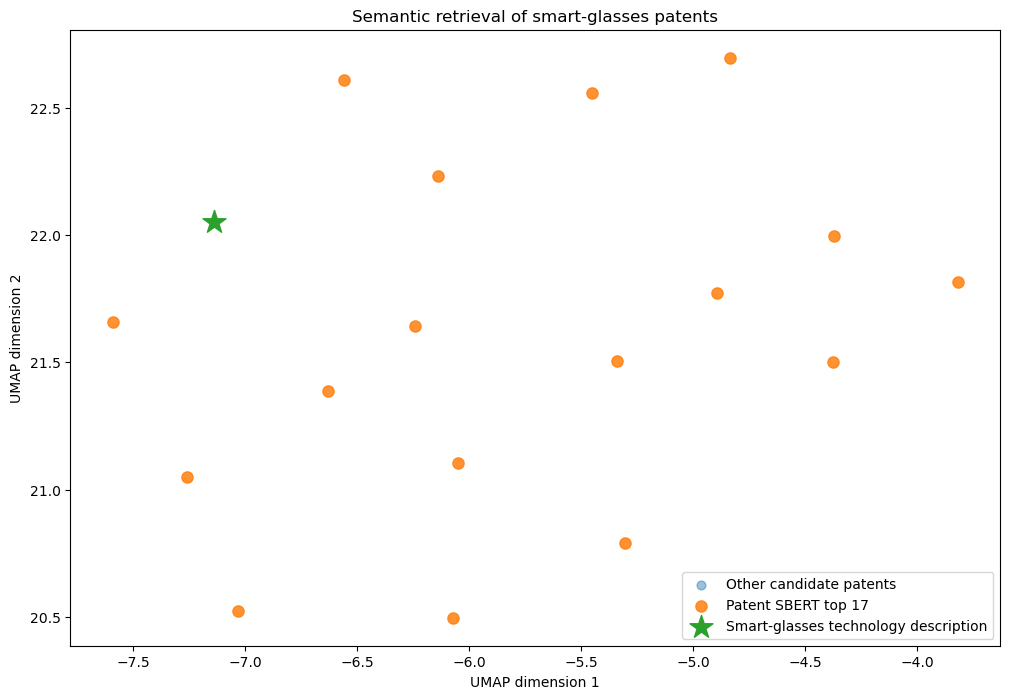

In [37]:

# 6.7 Visualising the semantic space with UMAP
# Smart glasses patent retrieval

import numpy as np
import matplotlib.pyplot as plt
import umap

# Project patent abstract embeddings and the smart-glasses
# technology description into the same 2D space.
umap_input = np.vstack([
    abstract_embeddings,
    smart_glasses_embedding.reshape(1, -1),
])

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=min(15, len(umap_input) - 1),
    min_dist=0.1,
    metric="cosine",
    random_state=RANDOM_STATE,
)

coords = reducer.fit_transform(umap_input)

# Store coordinates for the patent applications
candidates[["UMAP_1", "UMAP_2"]] = coords[:-1]

# Coordinates for the smart-glasses description
smart_glasses_xy = coords[-1]


def plot_retrieval_map(
    df,
    highlight_col,
    highlight_label,
    title,
    query_xy=smart_glasses_xy,
):
    """Plot candidate patents and highlight those retrieved by a method."""

    selected = df[df[highlight_col]]
    background = df[~df[highlight_col]]

    fig, ax = plt.subplots(figsize=(12, 8))

    ax.scatter(
        background["UMAP_1"],
        background["UMAP_2"],
        s=40,
        alpha=0.45,
        label="Other candidate patents",
    )

    ax.scatter(
        selected["UMAP_1"],
        selected["UMAP_2"],
        s=65,
        alpha=0.85,
        label=highlight_label,
    )

    ax.scatter(
        *query_xy,
        marker="*",
        s=300,
        label="Smart-glasses technology description",
    )

    ax.set_xlabel("UMAP dimension 1")
    ax.set_ylabel("UMAP dimension 2")
    ax.set_title(title)
    ax.legend()
    plt.show()


plot_retrieval_map(
    candidates,
    highlight_col="in_bm25_top",
    highlight_label=f"BM25 top {k}",
    title="BM25 retrieval of smart-glasses patents",
)

plot_retrieval_map(
    candidates,
    highlight_col="in_sbert_top",
    highlight_label=f"Patent SBERT top {k}",
    title="Semantic retrieval of smart-glasses patents",
)
